In [35]:
from google_play_scraper import Sort, reviews
import pandas as pd
import time
import os
import glob
import re


In [ ]:
apps = {
    'Flo': 'org.iggymedia.periodtracker',
    'Clue': 'com.clue.android',
    'Premom': 'com.easyhealthcare.premom',
    'NaturalCycles': 'com.naturalcycles.fertile',
    'Stardust': 'app.stardust.periodtracker'
}

regions = [
    {'country': 'us', 'lang': 'en', 'label': 'us'},
    {'country': 'it', 'lang': 'it', 'label': 'it'},
    {'country': 'gb', 'lang': 'en', 'label': 'uk'}
]

In [ ]:
path = 'thesis_data_large' 
all_files = glob.glob(os.path.join(path, "*.csv"))

li = []
for filename in all_files:
    df = pd.read_csv(filename, index_col=None, header=0)
    li.append(df)

master_df = pd.concat(li, axis=0, ignore_index=True)

print(f"Number of lines before cleaning: {len(master_df)}")
master_df.dropna(subset=['review'], inplace=True)
master_df.drop_duplicates(subset=['review', 'date', 'app_name'], inplace=True)

master_df['date'] = pd.to_datetime(master_df['date'])

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

master_df['review_clean'] = master_df['review'].apply(clean_text)

print(f"Number of lines after cleaning: {len(master_df)} unique reviews")
print(master_df.sample(15)[['app_name', 'region', 'review_clean']])

master_df.to_csv('master_dataset.csv', index=False)

Number of lines before cleaning: 79053
Number of lines after cleaning: 49053 unique reviews
      app_name region                                       review_clean
38587      Flo     it                                             ottimo
26315     Clue     uk  i really wish more of the articles were free t...
11067      Flo     us  l love this app it's easy to use, it helps to ...
16072     Clue     uk                                                  💯
34535     Clue     it                                        molto utile
38882      Flo     it                                             ottima
9046       Flo     us           i love the interface and personalisation
2598       Flo     us                                          it's good
26980     Clue     uk  keeping the track of dates as well as the capa...
26344     Clue     uk  i have been using clue for a few years now. it...
31314     Clue     it                ottima, non potrei più farne a meno
861        Flo     us  this work

In [ ]:
from google_play_scraper import reviews, Sort
import pandas as pd
import time
import os

apps = {
    'Flo':           'org.iggymedia.periodtracker',
    'Clue':          'com.clue.android',
    'Premom':        'premom.eh.com.ehpremomapp',
    'NaturalCycles': 'com.naturalcycles.cordova',
    'Stardust':      'com.stardust.app'
}

os.makedirs('thesis_data_android', exist_ok=True)
all_dfs = []

for name, package_id in apps.items():
    print(f"Collecting {name}...")
    try:
        result, _ = reviews(
            package_id,
            lang='en',
            country='us',
            sort=Sort.NEWEST,
            count=5000
        )
        df = pd.DataFrame(result)[['userName', 'score', 'at', 'content', 'thumbsUpCount']]
        df.rename(columns={'score': 'rating', 'at': 'date', 'content': 'review'}, inplace=True)
        df['app_name'] = name
        df['source'] = 'google_play'
        df.to_csv(f'thesis_data_android/{name.lower()}_android.csv', index=False)
        all_dfs.append(df)
        print(f"{len(df)} reviews")
        time.sleep(2)
    except Exception as e:
        print(f"{name}: {e}")

combined_android = pd.concat(all_dfs, ignore_index=True)
combined_android.to_csv('thesis_data_android/all_android_combined.csv', index=False)
print(f"\nAndroid total: {len(combined_android)} reviews")
print(combined_android.groupby('app_name')['rating'].count().to_string())

  ✅ 5000 reviews
  ✅ 5000 reviews
  ✅ 5000 reviews
  ✅ 4509 reviews
  ✅ 5000 reviews

✅ Android total: 24509 reviews
app_name
Clue             5000
Flo              5000
NaturalCycles    4509
Premom           5000
Stardust         5000


In [ ]:
%pip install app-store-scraper

Note: you may need to restart the kernel to use updated packages.


In [41]:
r = requests.get(
    "https://itunes.apple.com/us/rss/customerreviews/page=1/id=1038369065/sortby=mostrecent/json",
    headers={'User-Agent': 'Mozilla/5.0'},
    timeout=15
)
print(f"Length: {len(r.text)}")
print(r.text[:2000])

Length: 42685
{"feed":{"author":{"name":{"label":"iTunes Store"}, "uri":{"label":"http://www.apple.com/itunes/"}}, "entry":[
{"author":{"uri":{"label":"https://itunes.apple.com/us/reviews/id1101804534"}, "name":{"label":"NouveauMoi"}, "label":""}, "updated":{"label":"2026-05-12T22:23:01-07:00"}, "im:rating":{"label":"5"}, "im:version":{"label":"9.104.1"}, "id":{"label":"14058732720"}, "title":{"label":"It’s a nice app but weird too"}, "content":{"label":"My only issue so far is all the sex. There is nothing wrong with sex but I already checked the box that I’m not sexually active so why am I then forced to answer more and more questions about sex and self pleasure. I downloaded the app to track my period, that’s it. I did not download flo to learn about sex. Imagining 13 year old girls just wanting to track their and learn about their period and the app won’t shut up about sex all the time. Sex tips, sex advice, how to pleasure yourself. It’s absolutely unnecessary. That should be rest

In [42]:
search_terms = {
    'Flo': 'flo period cycle tracker',
    'Clue': 'clue period cycle tracker',
    'Premom': 'premom ovulation tracker',
    'NaturalCycles': 'natural cycles birth control',
    'Stardust': 'stardust period tracker'
}

for app_name, term in search_terms.items():
    r = requests.get(
        f"https://itunes.apple.com/search?term={term}&country=us&entity=software&limit=3",
        timeout=10
    )
    results = r.json()['results']
    print(f"\n{app_name}:")
    for app in results:
        print(f"  {app['trackName']} → {app['trackId']}")
    time.sleep(0.5)


Flo:
  Flo Cycle & Period Tracker → 1038369065
  MyFlo® Period Tracker Calendar → 1152657123
  Period Tracker Period Calendar → 896501514

Clue:
  Clue Period & Cycle Tracker → 657189652
  Simple Period Tracker → 6740041814
  Flo Cycle & Period Tracker → 1038369065

Premom:
  Premom Ovulation Tracker & BBT → 1279295922
  Flo Cycle & Period Tracker → 1038369065
  Pregmate Ovulation Tracker → 1610694094

NaturalCycles:
  Natural Cycles Fertility App → 765535549
  Flo Cycle & Period Tracker → 1038369065
  Cycles: Period & Cycle Tracker → 577187307

Stardust:
  Stardust Period Tracker → 1495829322
  Flo Cycle & Period Tracker → 1038369065
  Clue Period & Cycle Tracker → 657189652


In [ ]:
apps = {
    'Flo':           '1038369065',
    'Clue':          '657189652',
    'Premom':        '1279295922',
    'NaturalCycles': '765535549',
    'Stardust':      '1495829322'
}

countries = ['us', 'gb', 'it']

os.makedirs('thesis_data_ios', exist_ok=True)
all_dfs = []

def fetch_reviews_itunes(app_id, app_name, country='us', max_pages=10):
    all_reviews = []
    for page in range(1, max_pages + 1):
        url = (
            f"https://itunes.apple.com/{country}/rss/customerreviews/"
            f"page={page}/id={app_id}/sortby=mostrecent/json"
        )
        try:
            r = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}, timeout=15)
            data = r.json()
            entries = data.get('feed', {}).get('entry', [])
            if not entries:
                break
            if page == 1:
                entries = entries[1:]
            for e in entries:
                all_reviews.append({
                    'date':     e.get('updated', {}).get('label', '')[:10],
                    'rating':   int(e.get('im:rating', {}).get('label', 0)),
                    'title':    e.get('title', {}).get('label', ''),
                    'review':   e.get('content', {}).get('label', ''),
                    'author':   e.get('author', {}).get('name', {}).get('label', ''),
                    'version':  e.get('im:version', {}).get('label', ''),
                    'app_name': app_name,
                    'region':   country,
                    'source':   'app_store'
                })
            time.sleep(1)
        except Exception as e:
            print(f"  error page {page}: {e}")
            break
    return all_reviews

for name, app_id in apps.items():
    for country in countries:
        print(f"Collecting {name} ({country.upper()})...")
        reviews_list = fetch_reviews_itunes(app_id, name, country=country, max_pages=10)
        
        if reviews_list:
            df = pd.DataFrame(reviews_list)
            df.to_csv(f'thesis_data_ios/{name.lower()}_{country}_ios.csv', index=False)
            all_dfs.append(df)
            print(f"{len(df)} reviews")
        else:
            print(f"no reviews")
        
        time.sleep(2)

combined = pd.concat(all_dfs, ignore_index=True)
combined.to_csv('thesis_data_ios/all_ios_combined.csv', index=False)

print(f"\nTotal: {len(combined)} reviews")
print(combined.groupby(['app_name', 'region'])['rating'].count().to_string())

  ✅ 499 reviews
  ✅ 499 reviews
  ✅ 499 reviews
  ✅ 499 reviews
  ✅ 499 reviews
  ✅ 499 reviews
  ✅ 499 reviews
  ✅ 267 reviews
  ✅ 89 reviews
  ✅ 499 reviews
  ✅ 499 reviews
  ✅ 17 reviews
  ✅ 499 reviews
  ✅ 499 reviews
  ✅ 29 reviews

✅ Total: 5891 reviews
app_name       region
Clue           gb        499
               it        499
               us        499
Flo            gb        499
               it        499
               us        499
NaturalCycles  gb        499
               it         17
               us        499
Premom         gb        267
               it         89
               us        499
Stardust       gb        499
               it         29
               us        499


In [ ]:
from google_play_scraper import reviews, Sort
import pandas as pd
import glob
import time
import os

missing_apps = {
    'Premom':        'com.easialong.premom',
    'NaturalCycles': 'com.naturalcycles.cordova',
    'Stardust':      'com.stardust.period.tracker.fertility.app'
}

os.makedirs('thesis_data_large', exist_ok=True)

for name, package_id in missing_apps.items():
    print(f"Collecting {name}...")
    try:
        result, _ = reviews(
            package_id,
            lang='en',
            country='us',
            sort=Sort.NEWEST,
            count=5000
        )
        df = pd.DataFrame(result)[['userName', 'score', 'at', 'content', 'thumbsUpCount']]
        df.rename(columns={'score': 'rating', 'at': 'date', 'content': 'review'}, inplace=True)
        df['app_name'] = name
        df['source'] = 'google_play'
        df.to_csv(f'thesis_data_large/{name.lower()}_us.csv', index=False)
        print(f"{len(df)} reviews")
        time.sleep(2)
    except Exception as e:
        print(f"  ❌ {name}: {e}")

print("\nMerging all files...")

all_files = glob.glob('thesis_data_large/*.csv') + glob.glob('thesis_data_ios/*.csv')
all_files = [f for f in all_files if 'combined' not in f]

dfs = []
for f in all_files:
    df = pd.read_csv(f)
    if 'source' not in df.columns:
        df['source'] = 'google_play' if 'large' in f else 'app_store'
    dfs.append(df)

cols = ['date', 'rating', 'review', 'app_name', 'source']

dfs_filtered = []
for df in dfs:
    available = [c for c in cols if c in df.columns]
    dfs_filtered.append(df[available])

combined = pd.concat(dfs_filtered, ignore_index=True)
combined = combined.dropna(subset=['review'])
combined = combined.drop_duplicates(subset=['review', 'app_name'])
combined['date'] = pd.to_datetime(combined['date'], errors='coerce')

combined.to_csv('thesis_data/master_reviews.csv', index=False)

print(f"\nMaster dataset: {len(combined)} reviews")
print(combined.groupby(['app_name', 'source'])['rating'].count().to_string())

  ❌ Premom: "None of [Index(['userName', 'score', 'at', 'content', 'thumbsUpCount'], dtype='object')] are in the [columns]"
  ✅ 4509 reviews
  ❌ Stardust: "None of [Index(['userName', 'score', 'at', 'content', 'thumbsUpCount'], dtype='object')] are in the [columns]"

Merging all files...

✅ Master dataset: 10265 reviews
app_name       source     
Clue           app_store      1497
Flo            app_store      1491
NaturalCycles  app_store      1015
               google_play    4382
Premom         app_store       853
Stardust       app_store      1027


In [59]:
import pandas as pd
import glob
import os

ios_files = [f for f in glob.glob('thesis_data_ios/*.csv') if 'combined' not in f]
android_files = [f for f in glob.glob('thesis_data_android/*.csv') if 'combined' not in f]

all_files = ios_files + android_files
print(f"Found {len(all_files)} files")

dfs = []
for f in all_files:
    df = pd.read_csv(f)
    if 'source' not in df.columns:
        df['source'] = 'app_store' if 'ios' in f else 'google_play'
    cols = ['date', 'rating', 'review', 'app_name', 'source']
    df = df[[c for c in cols if c in df.columns]]
    dfs.append(df)

combined = pd.concat(dfs, ignore_index=True)
combined = combined.dropna(subset=['review'])
combined = combined.drop_duplicates(subset=['review', 'app_name'])
combined['date'] = pd.to_datetime(combined['date'], errors='coerce')

os.makedirs('thesis_data', exist_ok=True)
combined.to_csv('thesis_data/master_reviews.csv', index=False)

print(f"\nMaster dataset: {len(combined)} reviews")
print(combined.groupby(['app_name', 'source'])['rating'].count().to_string())

Found 20 files

Master dataset: 27960 reviews
app_name       source     
Clue           app_store      1497
               google_play    4524
Flo            app_store      1491
               google_play    3979
NaturalCycles  app_store      1015
               google_play    4382
Premom         app_store       853
               google_play    4262
Stardust       app_store      1027
               google_play    4930


In [60]:
pip install praw

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [praw]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from google_play_scraper import reviews, Sort
import pandas as pd
import time
import os

apps = {
    'Flo':           'org.iggymedia.periodtracker',
    'Clue':          'com.clue.android',
    'Premom':        'premom.eh.com.ehpremomapp',
    'NaturalCycles': 'com.naturalcycles.cordova',
    'Stardust':      'com.stardust.app'
}

os.makedirs('thesis_data_historical', exist_ok=True)
all_dfs = []

def scrape_until_date(package_id, app_name, target_year=2015, batch_size=5000):
    all_reviews = []
    continuation_token = None
    batch = 0
    
    while True:
        batch += 1
        print(f"  Batch {batch} ({len(all_reviews)} reviews so far)...")
        
        result, continuation_token = reviews(
            package_id,
            lang='en',
            country='us',
            sort=Sort.NEWEST,
            count=batch_size,
            continuation_token=continuation_token
        )
        
        if not result:
            print(f"  No more reviews.")
            break
        
        all_reviews.extend(result)
        last_date = pd.to_datetime(result[-1]['at'])
        print(f"  Last review date: {last_date.date()}")
        
        if last_date.year <= target_year:
            print(f"  Reached target year {target_year}, stopping.")
            break
        
        if continuation_token is None:
            print(f"No more pages.")
            break
        
        time.sleep(2)
    
    return all_reviews

for name, package_id in apps.items():
    print(f"\nCollecting {name} (historical)...")
    try:
        result = scrape_until_date(package_id, name, target_year=2015)
        
        df = pd.DataFrame(result)[['userName', 'score', 'at', 'content', 'thumbsUpCount']]
        df.rename(columns={'score': 'rating', 'at': 'date', 'content': 'review'}, inplace=True)
        df['app_name'] = name
        df['source'] = 'google_play'
        df['date'] = pd.to_datetime(df['date'])
        
        df = df[df['date'].dt.year >= 2015]
        df = df.drop_duplicates(subset=['review', 'app_name'])
        
        df.to_csv(f'thesis_data_historical/{name.lower()}_historical.csv', index=False)
        all_dfs.append(df)
        
        print(f"{len(df)} reviews ({df['date'].dt.year.min()}–{df['date'].dt.year.max()})")
        print(f"By year:\n{df.groupby(df['date'].dt.year)['rating'].count().to_string()}")
        
    except Exception as e:
        print(f"{name}: {e}")

combined = pd.concat(all_dfs, ignore_index=True)
combined.to_csv('thesis_data_historical/all_historical_combined.csv', index=False)
print(f"\nTotal historical: {len(combined)} reviews")


  Batch 1 (0 reviews so far)...
  Last review date: 2026-01-12
  Batch 2 (5000 reviews so far)...
  Last review date: 2025-08-27
  Batch 3 (10000 reviews so far)...
  Last review date: 2025-05-17
  Batch 4 (15000 reviews so far)...
  Last review date: 2025-02-12
  Batch 5 (20000 reviews so far)...
  Last review date: 2024-11-21
  Batch 6 (25000 reviews so far)...
  Last review date: 2024-08-14
  Batch 7 (30000 reviews so far)...
  Last review date: 2024-05-29
  Batch 8 (35000 reviews so far)...
  Last review date: 2024-02-20
  Batch 9 (40000 reviews so far)...
  Last review date: 2023-10-31
  Batch 10 (45000 reviews so far)...
  Last review date: 2023-06-21
  Batch 11 (50000 reviews so far)...
  Last review date: 2023-02-02
  Batch 12 (55000 reviews so far)...
  Last review date: 2022-09-04
  Batch 13 (60000 reviews so far)...
  Last review date: 2022-05-29
  Batch 14 (65000 reviews so far)...
  Last review date: 2022-04-16
  Batch 15 (70000 reviews so far)...
  Last review date: 2021

In [ ]:
import requests
import pandas as pd
import time
import os

apps = {
    'Flo':           '1038369065',
    'Clue':          '657189652',
    'Premom':        '1279295922',
    'NaturalCycles': '765535549',
    'Stardust':      '1495829322'
}

countries = ['us', 'gb', 'it', 'au', 'ca', 'de', 'fr', 'es', 'mx', 'in']

os.makedirs('thesis_data_ios', exist_ok=True)
all_dfs = []

def fetch_ios_reviews(app_id, app_name, country, max_pages=10):
    all_reviews = []
    for page in range(1, max_pages + 1):
        url = (f"https://itunes.apple.com/{country}/rss/customerreviews/"
               f"page={page}/id={app_id}/sortby=mostrecent/json")
        try:
            r = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}, timeout=15)
            data = r.json()
            entries = data.get('feed', {}).get('entry', [])
            if not entries:
                break
            if page == 1:
                entries = entries[1:]
            for e in entries:
                all_reviews.append({
                    'date':     e.get('updated', {}).get('label', '')[:10],
                    'rating':   int(e.get('im:rating', {}).get('label', 0)),
                    'review':   e.get('content', {}).get('label', ''),
                    'app_name': app_name,
                    'source':   'app_store'
                })
            time.sleep(0.5)
        except Exception as e:
            break
    return all_reviews

for name, app_id in apps.items():
    print(f"\nCollecting {name} (iOS)...")
    app_reviews = []
    for country in countries:
        reviews_list = fetch_ios_reviews(app_id, name, country)
        app_reviews.extend(reviews_list)
        print(f"  {country.upper()}: {len(reviews_list)} reviews")
        time.sleep(1)
    
    if app_reviews:
        df = pd.DataFrame(app_reviews)
        df = df.drop_duplicates(subset=['review', 'app_name'])
        df.to_csv(f'thesis_data_ios/{name.lower()}_ios.csv', index=False)
        all_dfs.append(df)
        print(f"{name} total: {len(df)} reviews")

combined_ios = pd.concat(all_dfs, ignore_index=True)
combined_ios.to_csv('thesis_data_ios/all_ios_combined.csv', index=False)
print(f"\niOS total: {len(combined_ios)} reviews")
print(combined_ios.groupby('app_name')['rating'].count().to_string())


  US: 499 reviews
  GB: 499 reviews
  IT: 499 reviews
  AU: 499 reviews
  CA: 499 reviews
  DE: 499 reviews
  FR: 499 reviews
  ES: 499 reviews
  MX: 499 reviews
  IN: 499 reviews
  ✅ Flo total: 4914 reviews

  US: 499 reviews
  GB: 499 reviews
  IT: 499 reviews
  AU: 499 reviews
  CA: 499 reviews
  DE: 499 reviews
  FR: 499 reviews
  ES: 499 reviews
  MX: 499 reviews
  IN: 199 reviews
  ✅ Clue total: 4679 reviews

  US: 499 reviews
  GB: 267 reviews
  IT: 89 reviews
  AU: 39 reviews
  CA: 386 reviews
  DE: 78 reviews
  FR: 53 reviews
  ES: 144 reviews
  MX: 24 reviews
  IN: 40 reviews
  ✅ Premom total: 1610 reviews

  US: 499 reviews
  GB: 499 reviews
  IT: 17 reviews
  AU: 189 reviews
  CA: 277 reviews
  DE: 78 reviews
  FR: 49 reviews
  ES: 41 reviews
  MX: 19 reviews
  IN: 0 reviews
  ✅ NaturalCycles total: 1668 reviews

  US: 499 reviews
  GB: 499 reviews
  IT: 29 reviews
  AU: 371 reviews
  CA: 499 reviews
  DE: 126 reviews
  FR: 36 reviews
  ES: 48 reviews
  MX: 47 reviews
  IN

In [ ]:
import pandas as pd
import os

android = pd.read_csv('thesis_data_historical/all_historical_combined.csv')
android['source'] = 'google_play'
print(f"Android (historical): {len(android)} reviews")

# загружаем iOS
ios = pd.read_csv('thesis_data_ios/all_ios_combined.csv')
ios['source'] = 'app_store'
print(f"iOS: {len(ios)} reviews")

cols = ['date', 'rating', 'review', 'app_name', 'source']

android = android[[c for c in cols if c in android.columns]]
ios = ios[[c for c in cols if c in ios.columns]]

master = pd.concat([android, ios], ignore_index=True)
master = master.dropna(subset=['review'])
master = master[master['review'].str.strip() != '']
master = master.drop_duplicates(subset=['review', 'app_name'])
master['date'] = pd.to_datetime(master['date'], errors='coerce')

os.makedirs('thesis_data', exist_ok=True)
master.to_csv('thesis_data/master_reviews.csv', index=False)

print(f"\nMASTER DATASET: {len(master)} reviews")
print(f"Period: {master['date'].min().date()} → {master['date'].max().date()}")
print("\nBy app and source:")
print(master.groupby(['app_name', 'source'])['rating'].count().to_string())
print("\nBy year:")
print(master.groupby(master['date'].dt.year)['rating'].count().to_string())

Android (historical): 221871 reviews
iOS: 15042 reviews

MASTER DATASET: 236718 reviews
Period: 2015-01-01 → 2026-05-14

By app and source:
app_name       source     
Clue           app_store        4640
               google_play     57443
Flo            app_store        4790
               google_play    149756
NaturalCycles  app_store        1666
               google_play      4373
Premom         app_store        1589
               google_play      5095
Stardust       app_store        2169
               google_play      5197

By year:
date
2015.0     1249
2016.0     5298
2017.0    27130
2018.0    23242
2019.0    28704
2020.0    33749
2021.0    26088
2022.0    16900
2023.0    16254
2024.0    19344
2025.0    17903
2026.0     6003


In [ ]:
import pandas as pd
import glob
import os

ios_files = glob.glob('thesis_data_ios/*.csv')
android_files = glob.glob('thesis_data_android/*.csv')

all_files = ios_files + android_files
all_files = [f for f in all_files if 'combined' not in f]

print(f"Found {len(all_files)} files:")
for f in all_files:
    print(f"  {f}")

dfs = []
for f in all_files:
    df = pd.read_csv(f)
    
    if 'source' not in df.columns:
        df['source'] = 'app_store' if 'ios' in f else 'google_play'
    
    cols = ['date', 'rating', 'review', 'app_name', 'source']
    df = df[[c for c in cols if c in df.columns]]
    dfs.append(df)

combined = pd.concat(dfs, ignore_index=True)
combined = combined.dropna(subset=['review'])
combined = combined.drop_duplicates(subset=['review', 'app_name'])
combined['date'] = pd.to_datetime(combined['date'], errors='coerce')

os.makedirs('thesis_data', exist_ok=True)
combined.to_csv('thesis_data/master_reviews.csv', index=False)

print(f"\n✅ Master dataset: {len(combined)} reviews")
print(combined.groupby(['app_name', 'source'])['rating'].count().to_string())

Found 18 files:
  thesis_data_ios/clue_it_ios.csv
  thesis_data_ios/clue_us_ios.csv
  thesis_data_ios/naturalcycles_gb_ios.csv
  thesis_data_ios/stardust_us_ios.csv
  thesis_data_ios/premom_gb_ios.csv
  thesis_data_ios/stardust_it_ios.csv
  thesis_data_ios/flo_gb_ios.csv
  thesis_data_ios/clue_gb_ios.csv
  thesis_data_ios/naturalcycles_it_ios.csv
  thesis_data_ios/naturalcycles_us_ios.csv
  thesis_data_ios/stardust_gb_ios.csv
  thesis_data_ios/flo_it_ios.csv
  thesis_data_ios/premom_us_ios.csv
  thesis_data_ios/premom_it_ios.csv
  thesis_data_ios/flo_us_ios.csv
  thesis_data_android/naturalcycles_android.csv
  thesis_data_android/clue_android.csv
  thesis_data_android/flo_android.csv

✅ Master dataset: 18768 reviews
app_name       source     
Clue           app_store      1497
               google_play    4524
Flo            app_store      1491
               google_play    3979
NaturalCycles  app_store      1015
               google_play    4382
Premom         app_store       853
St

In [81]:
%pip install google-api-python-client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.2/15.2 MB 31.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 31.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14/14 [google-api-python-client]api-python-client]
Note: you may need to restart the kernel to use updated packages.


In [95]:
from googleapiclient.discovery import build
import time

API_KEY = 'YOUR_API_KEY' 

video_ids = [
    # --- Flo ---
    'ILVMH4pP7c4', # How to Delete Your Flo Period Tracker Data [Privacy]
    'Z84s9c91zC0', # Flo App TRIAL UPDATE
    'WLslQomtnAg', # Delete Flo: Your Period Privacy is Big Business
    'c_9yl9AD4_U', # Flo App SCANDAL - What Flo didn't tell you!
    
    # --- Clue ---
    'M93w3kEZYXA', # Clue App Review | Doctor Evaluates Privacy & Safety
    '08S_6SbqbGc', # The Truth about Cycle Tracking Apps and Your Health Data
    'pTPEOYh4d8g', # Period tracking apps this OBGYN recommends
    'P2UnmdM1Iuk', # I Ranked 6 Popular Period Tracking Apps: Privacy & Red Flags
    
    # --- Premom ---
    'CstUiy22kvY', # Is health data from period-tracking apps protected under HIPAA?
    
    # --- Natural Cycles ---
    '24ZY2JViBkk', # OB/GYN: My HONEST review of the Natural Cycles app
    'ASOwHTjjR4Y', # Why are period apps getting so popular? - BBC
    'P7MNlEfhH9Q', # Period-tracking apps pose risks for users: report
    
    # --- Stardust ---
    '3QfiaCM84Vc', # Stardust Period Tracker- Doctor Reviews App
    'iL55MmWrMhA', # How Period-Tracking Apps Can Be Used Against You
    'W5sw2nGBM0E'  # Stardust period tracker shares data too?

    # --- reviews and debates ---
    'XAw6zUn2LKo', # NowThis: Consider Privacy Concerns When Using a Period Tracking App
    'ySfamhARHlg', # ABC News: Popular period-tracking apps raise privacy concerns
    'ASOwHTjjR4Y', # BBC World Service: Why are period apps getting so popular?
    'QVZ5mvJraAE',
    'v=oR7_qat20vw',
    '92hLs-CxUWs'
    
    # --- tech reviews of privacy ---
    '2wxI6GtdspI', # Side Of Burritos (Tech): Period tracking app Roe v Wade
    '-lwwETd4uTw', # Rob Braxman (Tech & Privacy stream)
    
    # --- big reviews from doctors and scientists ---
    'P2UnmdM1Iuk', # Ranked 6 Popular Period Tracking Apps
    '08S_6SbqbGc', # The Truth about Cycle Tracking Apps
    '24ZY2JViBkk', # OB/GYN review of Natural Cycles
    'pTPEOYh4d8g', # OB/GYN Period tracking apps recommended
    
    # --- Scandals) ---
    'CstUiy22kvY', # Is health data protected under HIPAA?
    'Z84s9c91zC0', # Flo App TRIAL UPDATE
    'M93w3kEZYXA', # Clue App Review (Doctor Evaluates Privacy)
    '3QfiaCM84Vc'  # Stardust Period Tracker Review

    # shorts
    'lJSMU3jOq_k', # "Roe v. Wade and period tracking apps | Are they safe?" (Simon Caine)
    'mWUpIkBrUJU', # "How safe are period tracking apps?" (NewsClickin)
    '0koScIvpANo', # "Period Tracking Apps Report You to Police" (American Human Rights)
    '6Z02yiM54iI', # "Best period tracking apps"
    'czbPVgdRDRM', '9h1nMT350o0', 'UCWUgOwR0Oc', 'en3htnGaorw'
]

print("connecting to youtube api")
youtube = build('youtube', 'v3', developerKey=API_KEY)

2026-05-18 22:59:57,629 [INFO] googleapiclient.discovery_cache - file_cache is only supported with oauth2client<4.0.0


connecting to youtube api


In [96]:
yt_comments = []

for video_id in video_ids:
    print(f"collecting comments from video: {video_id}...")
    try:
        request = youtube.commentThreads().list(
            part="snippet,replies", 
            videoId=video_id,
            maxResults=100, 
            textFormat="plainText"
        )
        
        page_count = 0
        while request and page_count < 50: 
            response = request.execute()
            
            for item in response['items']:
                top_comment = item['snippet']['topLevelComment']['snippet']
                yt_comments.append({
                    'video_id': video_id,
                    'author': top_comment['authorDisplayName'],
                    'text': top_comment['textDisplay'],
                    'likes': top_comment['likeCount'],
                    'date': top_comment['publishedAt'],
                    'type': 'Top Comment'
                })

                if 'replies' in item:
                    for reply_item in item['replies']['comments']:
                        reply = reply_item['snippet']
                        yt_comments.append({
                            'video_id': video_id,
                            'author': reply['authorDisplayName'],
                            'text': reply['textDisplay'],
                            'likes': reply['likeCount'],
                            'date': reply['publishedAt'],
                            'type': 'Reply'
                        })
            
            page_count += 1
            
            request = youtube.commentThreads().list_next(request, response)
            time.sleep(1)
            
    except Exception as e:
        print(f"error with video {video_id}: {e}")

collecting comments from video: ILVMH4pP7c4...
collecting comments from video: Z84s9c91zC0...
collecting comments from video: WLslQomtnAg...
collecting comments from video: c_9yl9AD4_U...
collecting comments from video: M93w3kEZYXA...
collecting comments from video: 08S_6SbqbGc...
collecting comments from video: pTPEOYh4d8g...
collecting comments from video: P2UnmdM1Iuk...
collecting comments from video: CstUiy22kvY...
collecting comments from video: 24ZY2JViBkk...
collecting comments from video: ASOwHTjjR4Y...
collecting comments from video: P7MNlEfhH9Q...
collecting comments from video: 3QfiaCM84Vc...
collecting comments from video: iL55MmWrMhA...
collecting comments from video: W5sw2nGBM0EXAw6zUn2LKo...
error with video W5sw2nGBM0EXAw6zUn2LKo: <HttpError 404 when requesting https://youtube.googleapis.com/youtube/v3/commentThreads?part=snippet%2Creplies&videoId=W5sw2nGBM0EXAw6zUn2LKo&maxResults=100&textFormat=plainText&key=YOUR_GOOGLE_API_KEY&alt=json returned "The video identified b

In [97]:
if yt_comments:
    df_yt = pd.DataFrame(yt_comments)
    df_yt.to_csv('youtube_femtech_discussions.csv', index=False)
    print(df_yt['type'].value_counts())
    print(f"\nsaved {len(df_yt)} comments")
    
    print("\ntop 5: ")
    top_comments = df_yt.sort_values(by='likes', ascending=False).head(10)
    for idx, row in top_comments.iterrows():
        print(f"\n[{row['likes']} likes] {row['author']}:")
        print(f"«{row['text'][:200]}...»")
else:
    print("\nno comments")

type
Top Comment    584
Reply          435
Name: count, dtype: int64

saved 1019 comments

top 5: 

[203 likes] @MostlyCloudy:
«I've been tracking my cycle for years now. It's hilarious around ovulation time, because my husband cannot take his hands off me. He has no idea most times, and it makes me giggle so much....»

[182 likes] @18matts:
«The fact that we are slipping into this sort of world is beyond depressing....»

[144 likes] @MrFortuneCookie7:
«This is unacceptable.

Period....»

[138 likes] @jesslauren733125:
«Quitting birth control was the best decision I’ve made. My anxiety and depression are gone and I LOVE feeling the flows of womanhood, especially around ovulation (:...»

[137 likes] @Simply_London12:
«I think I’m gonna try the first one !!...»

[118 likes] @sierza:
«I only thing I don’t like about this app is that they put so much behind a paywall. There’s truly so many tween:teen girls just trying to learn about their body that might not have money for various r...»

[

In [98]:
df_main = pd.read_csv('thesis_data/master_reviews.csv')
df_yt = pd.read_csv('youtube_femtech_discussions.csv')

if 'review' in df_main.columns:
    df_main = df_main.rename(columns={'review': 'text'})

if 'app_name' not in df_yt.columns:
    df_yt['app_name'] = 'YouTube Video'

final_dataset = pd.concat([df_main, df_yt], ignore_index=True)
final_dataset = final_dataset.dropna(subset=['text'])
final_dataset.to_csv('thesis_data/final.csv', index=False)

print(f"final dataset: {len(final_dataset)} lines")
print(final_dataset.groupby(['app_name', 'source'])['text'].count().to_string())

final dataset: 237737 lines
app_name       source     
Clue           app_store        4640
               google_play     57443
Flo            app_store        4790
               google_play    149756
NaturalCycles  app_store        1666
               google_play      4373
Premom         app_store        1589
               google_play      5095
Stardust       app_store        2169
               google_play      5197


In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv('thesis_data/final.csv')

df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['year'] = df['date'].dt.year

/var/folders/pw/m0rkh2l51_b0zj4_25qwbjkw0000gp/T/ipykernel_23402/3433820860.py:6: DtypeWarning: Columns (5,6,8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('thesis_data/final.csv')


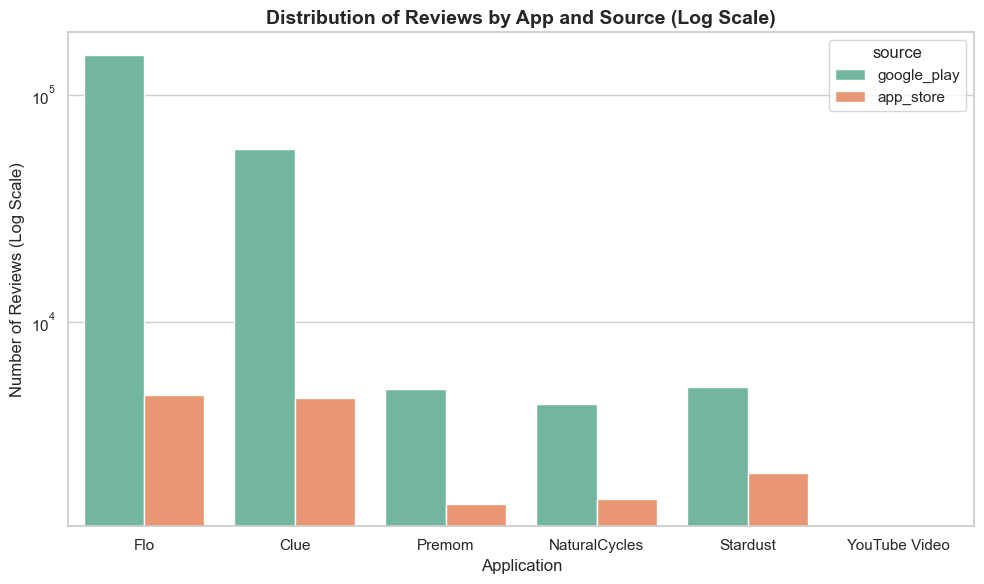

In [105]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='app_name', hue='source', palette='Set2')

plt.title('Distribution of Reviews by App and Source (Log Scale)', fontsize=14, fontweight='bold')
plt.xlabel('Application')
plt.ylabel('Number of Reviews (Log Scale)')
plt.yscale('log') 

plt.tight_layout()
plt.savefig('plot1_app_source_log.png', dpi=300)
plt.show()

2026-05-18 23:19:38,517 [INFO] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-18 23:19:38,519 [INFO] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


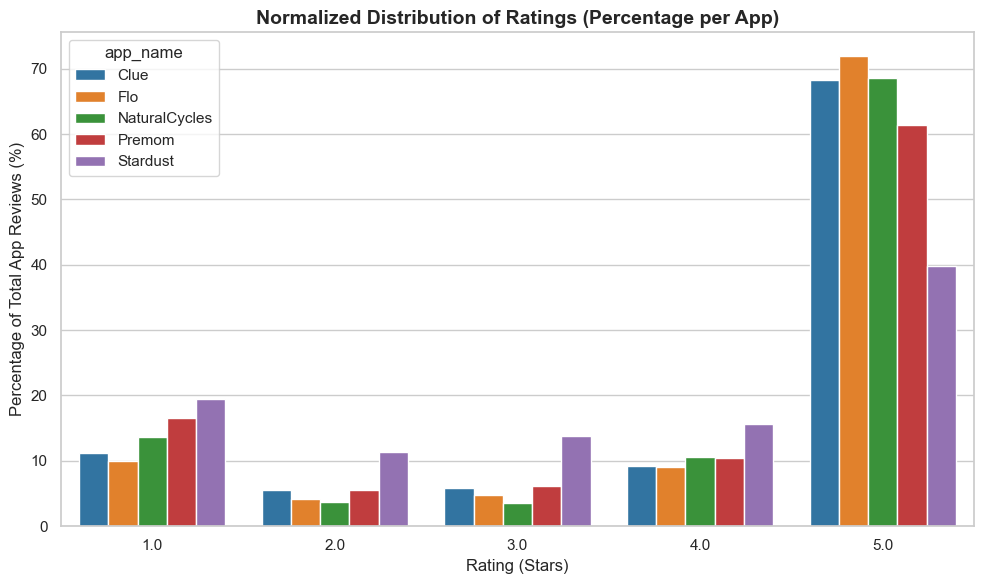

In [106]:
if 'rating' in df.columns:
    plt.figure(figsize=(10, 6))
    
    df_ratings = df.dropna(subset=['rating']).copy()
    
    rating_pct = (df_ratings.groupby(['app_name', 'rating']).size() / 
                  df_ratings.groupby('app_name').size()).reset_index(name='percentage')
    
    rating_pct['percentage'] *= 100
    
    sns.barplot(data=rating_pct, x='rating', y='percentage', hue='app_name', palette='tab10')
    
    plt.title('Normalized Distribution of Ratings (Percentage per App)', fontsize=14, fontweight='bold')
    plt.xlabel('Rating (Stars)')
    plt.ylabel('Percentage of Total App Reviews (%)')
    
    plt.tight_layout()
    plt.savefig('plot2_rating_normalized.png', dpi=300)
    plt.show()

In [107]:
plt.figure(figsize=(12, 6))

df_years = df[(df['year'] >= 2015) & (df['year'] <= 2026)].copy()
yearly_counts = df_years.groupby(['year', 'app_name']).size().reset_index(name='count')

sns.lineplot(data=yearly_counts, x='year', y='count', hue='app_name', marker='o', linewidth=2.5, palette='tab10')

plt.title('Review Volume Trends Over Time (2015 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Number of Reviews')

plt.xticks(df_years['year'].dropna().unique())
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plt.savefig('plot3_temporal_trends.png', dpi=300)
plt.show()